# Official DEA-Net: NHD Training and RESIDE / RESIDE-6K Testing

A Kaggle-ready notebook using the official DEA-Net training architecture, with the existing NHD training and NHD/RESIDE/RESIDE-6K paired benchmarking workflow.

## Setup Dependencies


In [1]:
%%capture
!pip -q install scikit-image --root-user-action=ignore

## Imports and Warning Control


In [2]:
import os
# Set before CUDA/PyTorch initialization; restart the Kaggle kernel, then Run All.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import json
import random
import warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


## Configuration
Update only the dataset paths if your Kaggle input slugs differ. The required folder layout is unchanged from `nhdv2`.


In [3]:
@dataclass
class CFG:
    ROOT: str = "/kaggle/input/datasets/mouryavardhanrathod/nhd-dataset-v1/NHD"
    INDEX_FILE: str = ""
    RESIDE_ROOT: str = "/kaggle/input/datasets/rathlavathramesh/reside/RESIDE_NHD/test"
    RESIDE6K_ROOT: str = "/kaggle/input/datasets/rathlavathramesh/reside-6k-dataset/test"
    IMAGE_SIZE: int = 192  # must be divisible by 4 for the two downsample/upsample stages
    BATCH_SIZE: int = 2
    ACCUM_STEPS: int = 4
    EPOCHS: int = 100
    LR: float = 1e-4
    WEIGHT_DECAY: float = 1e-4
    PATIENCE: int = 12
    NUM_WORKERS: int = 2
    SEED: int = 42
    OUT_DIR: str = "/kaggle/working/deanet_nhd"
    SELECTED_STRATEGIES: tuple = ("uniform", "fog_bank", "perlin", "radial", "depth_dep")

cfg = CFG()
cfg.INDEX_FILE = os.path.join(cfg.ROOT, "dataset_index.json")
os.makedirs(cfg.OUT_DIR, exist_ok=True)
assert cfg.IMAGE_SIZE % 4 == 0
print("Output dir:", cfg.OUT_DIR)

Output dir: /kaggle/working/deanet_nhd


## NHD Dataset Loader
NHD training/validation/test splits come from `dataset_index.json`. RESIDE and reside-6k use paired image folders for external evaluation.


In [4]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
image_transform = transforms.Compose([
    transforms.Resize((cfg.IMAGE_SIZE, cfg.IMAGE_SIZE)),
    transforms.ToTensor(),
])

def list_images(folder):
    if not folder or not os.path.isdir(folder):
        return []
    return sorted(
        os.path.join(root, name)
        for root, _, files in os.walk(folder)
        for name in files
        if name.lower().endswith(IMAGE_EXTENSIONS)
    )

def normalize_pair_stem(path):
    stem = os.path.splitext(os.path.basename(path))[0].lower()
    for token in ("_hazy", "-hazy", " haze", "_gt", "-gt", "_clean", "-clean", "_clear", "-clear"):
        stem = stem.replace(token, "")
    return stem

def build_image_pairs_from_folders(hazy_dir, gt_dir):
    hazy_paths, gt_paths = list_images(hazy_dir), list_images(gt_dir)
    gt_by_stem = {normalize_pair_stem(path): path for path in gt_paths}
    pairs = [(hazy, gt_by_stem[normalize_pair_stem(hazy)]) for hazy in hazy_paths if normalize_pair_stem(hazy) in gt_by_stem]
    return pairs or (list(zip(hazy_paths, gt_paths)) if len(hazy_paths) == len(gt_paths) else [])

def find_paired_root(preferred, alternatives):
    for root in (preferred, *alternatives):
        if os.path.isdir(os.path.join(root, "hazy")) and os.path.isdir(os.path.join(root, "gt")):
            return root
    return None

class PairedDehazeDataset(Dataset):
    def __init__(self, pairs, dataset_name):
        self.pairs, self.dataset_name = pairs, dataset_name

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        hazy_path, gt_path = self.pairs[idx]
        hazy = Image.open(hazy_path).convert("RGB")
        gt = Image.open(gt_path).convert("RGB")
        return {
            "hazy": image_transform(hazy),
            "gt": image_transform(gt),
            "dataset": self.dataset_name,
            "img_id": os.path.basename(hazy_path),
        }

def build_nhd_pairs(split):
    if not os.path.isfile(cfg.INDEX_FILE):
        raise FileNotFoundError(f"NHD index not found: {cfg.INDEX_FILE}")
    with open(cfg.INDEX_FILE, "r") as f:
        metadata = json.load(f)
    pairs = []
    for item in metadata:
        if item.get("split") != split or item.get("strategy") not in cfg.SELECTED_STRATEGIES:
            continue
        hazy = os.path.join(cfg.ROOT, item["hazy_path"])
        gt = os.path.join(cfg.ROOT, item["gt_path"])
        if os.path.isfile(hazy) and os.path.isfile(gt):
            pairs.append((hazy, gt))
    return pairs

train_dataset = PairedDehazeDataset(build_nhd_pairs("train"), "NHD_dataset")
val_dataset = PairedDehazeDataset(build_nhd_pairs("val"), "NHD_dataset")
test_dataset = PairedDehazeDataset(build_nhd_pairs("test"), "NHD_dataset")
assert len(train_dataset) and len(val_dataset) and len(test_dataset), "NHD split is empty; check cfg.ROOT."

def make_loader(dataset, shuffle=False):
    return DataLoader(dataset, batch_size=cfg.BATCH_SIZE, shuffle=shuffle, num_workers=cfg.NUM_WORKERS, pin_memory=torch.cuda.is_available())

train_loader, val_loader, test_loader = make_loader(train_dataset, True), make_loader(val_dataset), make_loader(test_dataset)
print(f"NHD pairs — train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}")


NHD pairs — train: 560, val: 70, test: 70


## Official DEA-Net Architecture

This is DEA-Net’s official training backbone: detail-enhanced convolution (DEConv) blocks in a 3-scale encoder–decoder, DEA blocks with spatial/channel/pixel attention at the bottleneck, and content-guided attention (CGA) fusion of the decoder skip connections. The code is made self-contained by replacing the source’s device-specific temporary tensors with tensors allocated on the input’s device; the architecture is otherwise unchanged.

In [5]:
import math
import math
import torch
from torch import nn


class Conv2d_cd(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1,
                 padding=1, dilation=1, groups=1, bias=False, theta=1.0):

        super(Conv2d_cd, self).__init__() 
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation, groups=groups, bias=bias)
        self.theta = theta

    def get_weight(self):
        conv_weight = self.conv.weight
        conv_shape = conv_weight.shape
        conv_weight = conv_weight.reshape(conv_weight.shape[0], conv_weight.shape[1], -1)
        conv_weight_cd = conv_weight.new_zeros(conv_shape[0], conv_shape[1], 3 * 3)
        conv_weight_cd[:, :, :] = conv_weight[:, :, :]
        conv_weight_cd[:, :, 4] = conv_weight[:, :, 4] - conv_weight[:, :, :].sum(2)
        conv_weight_cd = conv_weight_cd.reshape(conv_shape[0], conv_shape[1], conv_shape[2], conv_shape[3])
        return conv_weight_cd, self.conv.bias


class Conv2d_ad(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1,
                 padding=1, dilation=1, groups=1, bias=False, theta=1.0):

        super(Conv2d_ad, self).__init__() 
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation, groups=groups, bias=bias)
        self.theta = theta

    def get_weight(self):
        conv_weight = self.conv.weight
        conv_shape = conv_weight.shape
        conv_weight = conv_weight.reshape(conv_weight.shape[0], conv_weight.shape[1], -1)
        conv_weight_ad = conv_weight - self.theta * conv_weight[:, :, [3, 0, 1, 6, 4, 2, 7, 8, 5]]
        conv_weight_ad = conv_weight_ad.reshape(conv_shape[0], conv_shape[1], conv_shape[2], conv_shape[3])
        return conv_weight_ad, self.conv.bias


class Conv2d_rd(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1,
                 padding=2, dilation=1, groups=1, bias=False, theta=1.0):

        super(Conv2d_rd, self).__init__() 
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation, groups=groups, bias=bias)
        self.theta = theta

    def forward(self, x):

        if math.fabs(self.theta - 0.0) < 1e-8:
            out_normal = self.conv(x)
            return out_normal 
        else:
            conv_weight = self.conv.weight
            conv_shape = conv_weight.shape
            if conv_weight.is_cuda:
                conv_weight_rd = conv_weight.new_zeros(conv_shape[0], conv_shape[1], 5 * 5)
            else:
                conv_weight_rd = conv_weight.new_zeros(conv_shape[0], conv_shape[1], 5 * 5)
            conv_weight = conv_weight.reshape(conv_weight.shape[0], conv_weight.shape[1], -1)
            conv_weight_rd[:, :, [0, 2, 4, 10, 14, 20, 22, 24]] = conv_weight[:, :, 1:]
            conv_weight_rd[:, :, [6, 7, 8, 11, 13, 16, 17, 18]] = -conv_weight[:, :, 1:] * self.theta
            conv_weight_rd[:, :, 12] = conv_weight[:, :, 0] * (1 - self.theta)
            conv_weight_rd = conv_weight_rd.view(conv_shape[0], conv_shape[1], 5, 5)
            out_diff = nn.functional.conv2d(input=x, weight=conv_weight_rd, bias=self.conv.bias, stride=self.conv.stride, padding=self.conv.padding, groups=self.conv.groups)

            return out_diff


class Conv2d_hd(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1,
                 padding=1, dilation=1, groups=1, bias=False, theta=1.0):

        super(Conv2d_hd, self).__init__() 
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation, groups=groups, bias=bias)

    def get_weight(self):
        conv_weight = self.conv.weight
        conv_shape = conv_weight.shape
        conv_weight_hd = conv_weight.new_zeros(conv_shape[0], conv_shape[1], 3 * 3)
        conv_weight_hd[:, :, [0, 3, 6]] = conv_weight[:, :, :]
        conv_weight_hd[:, :, [2, 5, 8]] = -conv_weight[:, :, :]
        conv_weight_hd = conv_weight_hd.reshape(conv_shape[0], conv_shape[1], conv_shape[2], conv_shape[2])
        return conv_weight_hd, self.conv.bias


class Conv2d_vd(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1,
                 padding=1, dilation=1, groups=1, bias=False):

        super(Conv2d_vd, self).__init__() 
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, dilation=dilation, groups=groups, bias=bias)

    def get_weight(self):
        conv_weight = self.conv.weight
        conv_shape = conv_weight.shape
        conv_weight_vd = conv_weight.new_zeros(conv_shape[0], conv_shape[1], 3 * 3)
        conv_weight_vd[:, :, [0, 1, 2]] = conv_weight[:, :, :]
        conv_weight_vd[:, :, [6, 7, 8]] = -conv_weight[:, :, :]
        conv_weight_vd = conv_weight_vd.reshape(conv_shape[0], conv_shape[1], conv_shape[2], conv_shape[2])
        return conv_weight_vd, self.conv.bias


class DEConv(nn.Module):
    def __init__(self, dim):
        super(DEConv, self).__init__() 
        self.conv1_1 = Conv2d_cd(dim, dim, 3, bias=True)
        self.conv1_2 = Conv2d_hd(dim, dim, 3, bias=True)
        self.conv1_3 = Conv2d_vd(dim, dim, 3, bias=True)
        self.conv1_4 = Conv2d_ad(dim, dim, 3, bias=True)
        self.conv1_5 = nn.Conv2d(dim, dim, 3, padding=1, bias=True)

    def forward(self, x):
        w1, b1 = self.conv1_1.get_weight()
        w2, b2 = self.conv1_2.get_weight()
        w3, b3 = self.conv1_3.get_weight()
        w4, b4 = self.conv1_4.get_weight()
        w5, b5 = self.conv1_5.weight, self.conv1_5.bias

        w = w1 + w2 + w3 + w4 + w5
        b = b1 + b2 + b3 + b4 + b5
        res = nn.functional.conv2d(input=x, weight=w, bias=b, stride=1, padding=1, groups=1)

        return res
import torch
from torch import nn


class SpatialAttention(nn.Module):
    def __init__(self):
        super(SpatialAttention, self).__init__()
        self.sa = nn.Conv2d(2, 1, 7, padding=3, padding_mode='reflect' ,bias=True)

    def forward(self, x):
        x_avg = torch.mean(x, dim=1, keepdim=True)
        x_max, _ = torch.max(x, dim=1, keepdim=True)
        x2 = torch.concat([x_avg, x_max], dim=1)
        sattn = self.sa(x2)
        return sattn


class ChannelAttention(nn.Module):
    def __init__(self, dim, reduction = 8):
        super(ChannelAttention, self).__init__()
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.ca = nn.Sequential(
            nn.Conv2d(dim, dim // reduction, 1, padding=0, bias=True),
            nn.ReLU(inplace=True),
            nn.Conv2d(dim // reduction, dim, 1, padding=0, bias=True),
        )

    def forward(self, x):
        x_gap = self.gap(x)
        cattn = self.ca(x_gap)
        return cattn


class PixelAttention(nn.Module):
    def __init__(self, dim):
        super(PixelAttention, self).__init__()
        self.pa2 = nn.Conv2d(2 * dim, dim, 7, padding=3, padding_mode='reflect' ,groups=dim, bias=True)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x, pattn1):
        B, C, H, W = x.shape
        x = x.unsqueeze(dim=2) # B, C, 1, H, W
        pattn1 = pattn1.unsqueeze(dim=2) # B, C, 1, H, W
        x2 = torch.cat([x, pattn1], dim=2) # B, C, 2, H, W
        x2 = x2.reshape(B, C * 2, H, W)
        pattn2 = self.pa2(x2)
        pattn2 = self.sigmoid(pattn2)
        return pattn2
from torch import nn



class DEABlockTrain(nn.Module):
    def __init__(self, conv, dim, kernel_size, reduction=8):
        super(DEABlockTrain, self).__init__()
        self.conv1 = DEConv(dim)
        self.act1 = nn.ReLU(inplace=True)
        self.conv2 = conv(dim, dim, kernel_size, bias=True)
        self.sa = SpatialAttention()
        self.ca = ChannelAttention(dim, reduction)
        self.pa = PixelAttention(dim)

    def forward(self, x):
        res = self.conv1(x)
        res = self.act1(res)
        res = res + x
        res = self.conv2(res)
        cattn = self.ca(res)
        sattn = self.sa(res)
        pattn1 = sattn + cattn
        pattn2 = self.pa(res, pattn1)
        res = res * pattn2
        res = res + x
        return res


class DEBlockTrain(nn.Module):
    def __init__(self, conv, dim, kernel_size):
        super(DEBlockTrain, self).__init__()
        self.conv1 = DEConv(dim)
        self.act1 = nn.ReLU(inplace=True)
        self.conv2 = conv(dim, dim, kernel_size, bias=True)

    def forward(self, x):
        res = self.conv1(x)
        res = self.act1(res)
        res = res + x
        res = self.conv2(res)
        res = res + x
        return res
from torch import nn



class CGAFusion(nn.Module):
    def __init__(self, dim, reduction=8):
        super(CGAFusion, self).__init__()
        self.sa = SpatialAttention()
        self.ca = ChannelAttention(dim, reduction)
        self.pa = PixelAttention(dim)
        self.conv = nn.Conv2d(dim, dim, 1, bias=True)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x, y):
        initial = x + y
        cattn = self.ca(initial)
        sattn = self.sa(initial)
        pattn1 = sattn + cattn
        pattn2 = self.sigmoid(self.pa(initial, pattn1))
        result = initial + pattn2 * x + (1 - pattn2) * y
        result = self.conv(result)
        return result
import torch.nn as nn
import torch.nn.functional as F



def default_conv(in_channels, out_channels, kernel_size, bias=True):
    return nn.Conv2d(in_channels, out_channels, kernel_size, padding=(kernel_size // 2), bias=bias)


class DEANet(nn.Module):
    def __init__(self, base_dim=32):
        super(DEANet, self).__init__()
        # down-sample
        self.down1 = nn.Sequential(nn.Conv2d(3, base_dim, kernel_size=3, stride = 1, padding=1))
        self.down2 = nn.Sequential(nn.Conv2d(base_dim, base_dim*2, kernel_size=3, stride=2, padding=1),
                                   nn.ReLU(True))
        self.down3 = nn.Sequential(nn.Conv2d(base_dim*2, base_dim*4, kernel_size=3, stride=2, padding=1),
                                   nn.ReLU(True))
        # level1
        self.down_level1_block1 = DEBlockTrain(default_conv, base_dim, 3)
        self.down_level1_block2 = DEBlockTrain(default_conv, base_dim, 3)
        self.down_level1_block3 = DEBlockTrain(default_conv, base_dim, 3)
        self.down_level1_block4 = DEBlockTrain(default_conv, base_dim, 3)
        self.up_level1_block1 = DEBlockTrain(default_conv, base_dim, 3)
        self.up_level1_block2 = DEBlockTrain(default_conv, base_dim, 3)
        self.up_level1_block3 = DEBlockTrain(default_conv, base_dim, 3)
        self.up_level1_block4 = DEBlockTrain(default_conv, base_dim, 3)
        # level2
        self.fe_level_2 = nn.Conv2d(in_channels=base_dim * 2, out_channels=base_dim * 2, kernel_size=3, stride=1, padding=1)
        self.down_level2_block1 = DEBlockTrain(default_conv, base_dim * 2, 3)
        self.down_level2_block2 = DEBlockTrain(default_conv, base_dim * 2, 3)
        self.down_level2_block3 = DEBlockTrain(default_conv, base_dim * 2, 3)
        self.down_level2_block4 = DEBlockTrain(default_conv, base_dim * 2, 3)
        self.up_level2_block1 = DEBlockTrain(default_conv, base_dim * 2, 3)
        self.up_level2_block2 = DEBlockTrain(default_conv, base_dim * 2, 3)
        self.up_level2_block3 = DEBlockTrain(default_conv, base_dim * 2, 3)
        self.up_level2_block4 = DEBlockTrain(default_conv, base_dim * 2, 3)
        # level3
        self.fe_level_3 = nn.Conv2d(in_channels=base_dim * 4, out_channels=base_dim * 4, kernel_size=3, stride=1, padding=1)
        self.level3_block1 = DEABlockTrain(default_conv, base_dim * 4, 3)
        self.level3_block2 = DEABlockTrain(default_conv, base_dim * 4, 3)
        self.level3_block3 = DEABlockTrain(default_conv, base_dim * 4, 3)
        self.level3_block4 = DEABlockTrain(default_conv, base_dim * 4, 3)
        self.level3_block5 = DEABlockTrain(default_conv, base_dim * 4, 3)
        self.level3_block6 = DEABlockTrain(default_conv, base_dim * 4, 3)
        self.level3_block7 = DEABlockTrain(default_conv, base_dim * 4, 3)
        self.level3_block8 = DEABlockTrain(default_conv, base_dim * 4, 3)
        # up-sample
        self.up1 = nn.Sequential(nn.ConvTranspose2d(base_dim*4, base_dim*2, kernel_size=3, stride=2, padding=1, output_padding=1),
                                 nn.ReLU(True))
        self.up2 = nn.Sequential(nn.ConvTranspose2d(base_dim*2, base_dim, kernel_size=3, stride=2, padding=1, output_padding=1),
                                 nn.ReLU(True))
        self.up3 = nn.Sequential(nn.Conv2d(base_dim, 3, kernel_size=3, stride=1, padding=1))
        # feature fusion
        self.mix1 = CGAFusion(base_dim * 4, reduction=8)
        self.mix2 = CGAFusion(base_dim * 2, reduction=4)

    def forward(self, x):
        x_down1 = self.down1(x)
        x_down1 = self.down_level1_block1(x_down1)
        x_down1 = self.down_level1_block2(x_down1)
        x_down1 = self.down_level1_block3(x_down1)
        x_down1 = self.down_level1_block4(x_down1)

        x_down2 = self.down2(x_down1)
        x_down2_init = self.fe_level_2(x_down2)
        x_down2_init = self.down_level2_block1(x_down2_init)
        x_down2_init = self.down_level2_block2(x_down2_init)
        x_down2_init = self.down_level2_block3(x_down2_init)
        x_down2_init = self.down_level2_block4(x_down2_init)

        x_down3 = self.down3(x_down2_init)
        x_down3_init = self.fe_level_3(x_down3)
        x1 = self.level3_block1(x_down3_init)
        x2 = self.level3_block2(x1)
        x3 = self.level3_block3(x2)
        x4 = self.level3_block4(x3)
        x5 = self.level3_block5(x4)
        x6 = self.level3_block6(x5)
        x7 = self.level3_block7(x6)
        x8 = self.level3_block8(x7)
        x_level3_mix = self.mix1(x_down3, x8)

        x_up1 = self.up1(x_level3_mix)
        x_up1 = self.up_level2_block1(x_up1)
        x_up1 = self.up_level2_block2(x_up1)
        x_up1 = self.up_level2_block3(x_up1)
        x_up1 = self.up_level2_block4(x_up1)

        x_level2_mix = self.mix2(x_down2, x_up1)
        x_up2 = self.up2(x_level2_mix)
        x_up2 = self.up_level1_block1(x_up2)
        x_up2 = self.up_level1_block2(x_up2)
        x_up2 = self.up_level1_block3(x_up2)
        x_up2 = self.up_level1_block4(x_up2)
        out = self.up3(x_up2)

        return out

model = DEANet(base_dim=32).to(device)
print(model)
print(f'DEA-Net trainable parameters: {sum(p.numel() for p in model.parameters()):,}')

DEANet(
  (down1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (down2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU(inplace=True)
  )
  (down3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU(inplace=True)
  )
  (down_level1_block1): DEBlockTrain(
    (conv1): DEConv(
      (conv1_1): Conv2d_cd(
        (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (conv1_2): Conv2d_hd(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(1,))
      )
      (conv1_3): Conv2d_vd(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(1,))
      )
      (conv1_4): Conv2d_ad(
        (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (conv1_5): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
    (act1): ReLU(inpla

## End-to-End Joint Training
Train DEA-Net directly on NHD paired hazy/clean images. The checkpoint with the highest validation PSNR is retained.


In [6]:
def charbonnier_loss(pred, target, eps=1e-3):
    return torch.mean(torch.sqrt((pred - target).pow(2) + eps * eps))

def batch_psnr(pred, target, eps=1e-8):
    mse = (pred - target).pow(2).flatten(1).mean(1).clamp_min(eps)
    return (10.0 * torch.log10(1.0 / mse)).mean()

def batch_ssim(pred, target, eps=1e-8):
    """Dependency-free global SSIM for training diagnostics (higher is better)."""
    x, y = pred.flatten(1), target.flatten(1)
    mux, muy = x.mean(1), y.mean(1)
    vx, vy = x.var(1, unbiased=False), y.var(1, unbiased=False)
    cov = ((x - mux[:, None]) * (y - muy[:, None])).mean(1)
    c1, c2 = 0.01 ** 2, 0.03 ** 2
    score = ((2 * mux * muy + c1) * (2 * cov + c2)) / ((mux.square() + muy.square() + c1) * (vx + vy + c2) + eps)
    return score.mean()

def loss_fn(pred, target):
    return charbonnier_loss(pred, target)

def evaluate(model, loader):
    model.eval(); losses, psnrs, ssims, maes = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            hazy = batch['hazy'].to(device, non_blocking=True)
            gt = batch['gt'].to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=amp_enabled):
                pred = model(hazy); loss = loss_fn(pred, gt)
            pred, gt = pred.float(), gt.float()
            losses.append(loss.float().item()); psnrs.append(batch_psnr(pred, gt).item()); ssims.append(batch_ssim(pred, gt).item()); maes.append(F.l1_loss(pred, gt).item())
    return {'loss': float(np.mean(losses)), 'psnr': float(np.mean(psnrs)), 'ssim': float(np.mean(ssims)), 'mae': float(np.mean(maes))}

amp_enabled = device.type == 'cuda'
scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)
optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=4)
history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'val_psnr': [], 'val_ssim': [], 'val_mae': []}
best_psnr, bad_epochs = -float('inf'), 0
checkpoint_path = os.path.join(cfg.OUT_DIR, 'best_deanet_nhd.pth')

for epoch in range(cfg.EPOCHS):
    model.train(); train_losses = []; optimizer.zero_grad(set_to_none=True)
    for step, batch in enumerate(tqdm(train_loader, desc=f'Epoch {epoch + 1}/{cfg.EPOCHS}', leave=False), start=1):
        hazy = batch['hazy'].to(device, non_blocking=True); gt = batch['gt'].to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=amp_enabled):
            loss = loss_fn(model(hazy), gt)
        scaler.scale(loss / cfg.ACCUM_STEPS).backward(); train_losses.append(loss.float().item())
        if step % cfg.ACCUM_STEPS == 0 or step == len(train_loader):
            scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
    val = evaluate(model, val_loader); train_loss = float(np.mean(train_losses))
    history['epoch'].append(epoch + 1); history['train_loss'].append(train_loss); history['val_loss'].append(val['loss']); history['val_psnr'].append(val['psnr']); history['val_ssim'].append(val['ssim']); history['val_mae'].append(val['mae'])
    scheduler.step(val['psnr'])
    print(f"Epoch {epoch + 1:03d} | train={train_loss:.5f} | val_loss={val['loss']:.5f} | val_psnr={val['psnr']:.2f} | val_ssim={val['ssim']:.4f} | val_mae={val['mae']:.5f}")
    if val['psnr'] > best_psnr:
        best_psnr, bad_epochs = val['psnr'], 0; torch.save(model.state_dict(), checkpoint_path)
    else:
        bad_epochs += 1
        if bad_epochs >= cfg.PATIENCE:
            print('Early stopping.'); break

model.load_state_dict(torch.load(checkpoint_path, map_location=device))
print('Best validation PSNR:', f'{best_psnr:.2f}', '| checkpoint:', checkpoint_path)

Epoch 1/100:   0%|          | 0/280 [00:00<?, ?it/s]

Epoch 001 | train=0.16619 | val_loss=0.12093 | val_psnr=16.59 | val_ssim=0.6880 | val_mae=0.12092


Epoch 2/100:   0%|          | 0/280 [00:00<?, ?it/s]

Epoch 002 | train=0.12272 | val_loss=0.10745 | val_psnr=17.43 | val_ssim=0.7816 | val_mae=0.10743


Epoch 3/100:   0%|          | 0/280 [00:00<?, ?it/s]

Epoch 003 | train=0.11656 | val_loss=0.09962 | val_psnr=18.06 | val_ssim=0.7996 | val_mae=0.09960


... (84 outputs left out)

Epoch 46/100:   0%|          | 0/280 [00:00<?, ?it/s]

Epoch 046 | train=0.02272 | val_loss=0.07965 | val_psnr=20.23 | val_ssim=0.8616 | val_mae=0.07963


Epoch 47/100:   0%|          | 0/280 [00:00<?, ?it/s]

Epoch 047 | train=0.02253 | val_loss=0.07944 | val_psnr=20.24 | val_ssim=0.8632 | val_mae=0.07941
Early stopping.
Best validation PSNR: 20.35 | checkpoint: /kaggle/working/deanet_nhd/best_deanet_nhd.pth


## Training Curves
Training Loss Curve, Validation Metric Curve, and MAE vs Epoch.


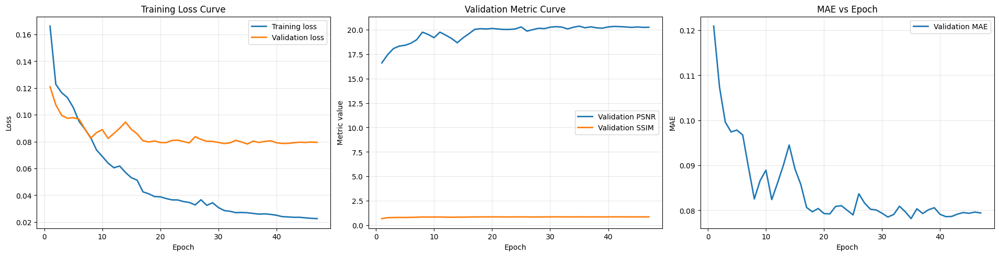

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), constrained_layout=True)
epochs = history["epoch"]
axes[0].plot(epochs, history["train_loss"], label="Training loss", linewidth=2)
axes[0].plot(epochs, history["val_loss"], label="Validation loss", linewidth=2)
axes[0].set(title="Training Loss Curve", xlabel="Epoch", ylabel="Loss")
axes[0].grid(alpha=.3); axes[0].legend()
axes[1].plot(epochs, history["val_psnr"], label="Validation PSNR", linewidth=2)
axes[1].plot(epochs, history["val_ssim"], label="Validation SSIM", linewidth=2)
axes[1].set(title="Validation Metric Curve", xlabel="Epoch", ylabel="Metric value")
axes[1].grid(alpha=.3); axes[1].legend()
axes[2].plot(epochs, history["val_mae"], label="Validation MAE", linewidth=2)
axes[2].set(title="MAE vs Epoch", xlabel="Epoch", ylabel="MAE")
axes[2].grid(alpha=.3); axes[2].legend()
plt.show()


## Test Protocol: NHD, RESIDE, and reside-6k
Every paired hazy image is dehazed and compared with its ground truth using PSNR, SSIM, MAE, and RMSE.


In [8]:
def dehaze_metrics(pred, gt):
    return {
        "PSNR": float(peak_signal_noise_ratio(gt, pred, data_range=1.0)),
        "SSIM": float(structural_similarity(gt, pred, channel_axis=-1, data_range=1.0)),
        "MAE": float(np.abs(pred.astype(np.float32) - gt.astype(np.float32)).mean()),
        "RMSE": float(np.sqrt(np.mean((pred.astype(np.float32) - gt.astype(np.float32)) ** 2))),
    }

def evaluate_dataset(model, dataset):
    records = []
    loader = make_loader(dataset)
    model.eval()
    with torch.no_grad():
        for batch in tqdm(loader, desc=f"Test {dataset.dataset_name}"):
            pred = model(batch["hazy"].to(device)).cpu()
            for i in range(pred.shape[0]):
                pred_np = pred[i].permute(1, 2, 0).numpy()
                gt_np = batch["gt"][i].permute(1, 2, 0).numpy()
                scores = dehaze_metrics(pred_np, gt_np)
                records.append({"dataset": dataset.dataset_name, "img_id": batch["img_id"][i], **scores})
    return pd.DataFrame(records)

reside_root = find_paired_root(cfg.RESIDE_ROOT, [
    "/kaggle/input/datasets/rathlavathramesh/reside/RESIDE_NHD",
    "/kaggle/input/reside-dataset-1/RESIDE_NHD/test",
    "/kaggle/input/reside/RESIDE_NHD/test",
])
reside6k_root = find_paired_root(cfg.RESIDE6K_ROOT, [
    "/kaggle/input/datasets/rathlavathramesh/reside-6k-dataset",
    "/kaggle/input/reside-6k-dataset/test",
    "/kaggle/input/reside6k-dataset/test",
])

test_datasets = {"NHD_dataset": test_dataset}
if reside_root:
    reside_dataset = PairedDehazeDataset(build_image_pairs_from_folders(os.path.join(reside_root, "hazy"), os.path.join(reside_root, "gt")), "RESIDE")
    if len(reside_dataset): test_datasets["RESIDE"] = reside_dataset
else:
    print("RESIDE not found; attach the dataset or update cfg.RESIDE_ROOT.")
if reside6k_root:
    reside6k_dataset = PairedDehazeDataset(build_image_pairs_from_folders(os.path.join(reside6k_root, "hazy"), os.path.join(reside6k_root, "gt")), "reside-6k")
    if len(reside6k_dataset): test_datasets["reside-6k"] = reside6k_dataset
else:
    print("reside-6k not found; attach the dataset or update cfg.RESIDE6K_ROOT.")

per_image_results = pd.concat([evaluate_dataset(model, ds) for ds in test_datasets.values()], ignore_index=True)
dataset_summary = per_image_results.groupby("dataset", as_index=False).agg(Images=("img_id", "count"), PSNR=("PSNR", "mean"), SSIM=("SSIM", "mean"), MAE=("MAE", "mean"), RMSE=("RMSE", "mean")).sort_values("dataset")
display(dataset_summary.style.format({"PSNR": "{:.4f}", "SSIM": "{:.4f}", "MAE": "{:.6f}", "RMSE": "{:.6f}"}))
per_image_results.to_csv(os.path.join(cfg.OUT_DIR, "deanet_per_image_results.csv"), index=False)
dataset_summary.to_csv(os.path.join(cfg.OUT_DIR, "deanet_dataset_summary.csv"), index=False)


Test NHD_dataset:   0%|          | 0/35 [00:00<?, ?it/s]

Test RESIDE:   0%|          | 0/100 [00:00<?, ?it/s]

Test reside-6k:   0%|          | 0/500 [00:00<?, ?it/s]

,dataset,Images,PSNR,SSIM,MAE,RMSE
0,NHD_dataset,70,20.5198,0.8547,0.076561,0.097344
1,RESIDE,200,18.3135,0.8117,0.101644,0.132158
2,reside-6k,1000,18.8471,0.7957,0.092762,0.119908


## PSNR Comparison


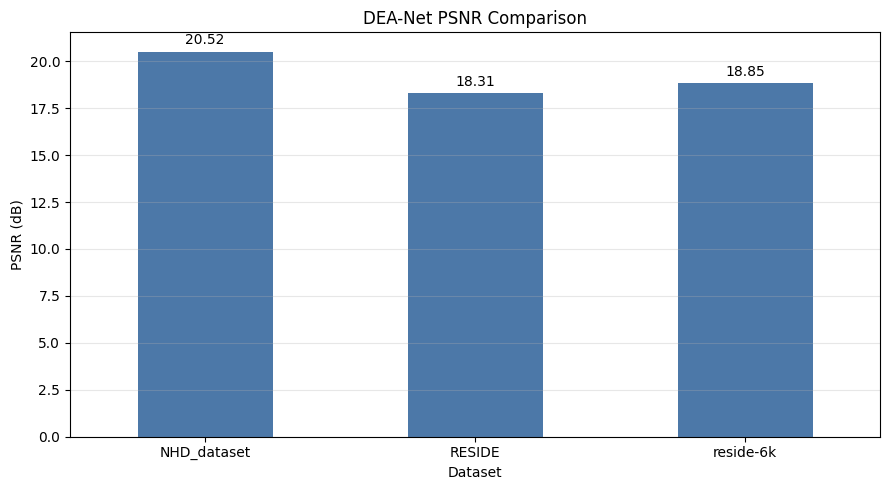

In [9]:
ax = dataset_summary.plot(x="dataset", y="PSNR", kind="bar", legend=False, figsize=(9, 5), color="#4C78A8")
ax.set(title="DEA-Net PSNR Comparison", xlabel="Dataset", ylabel="PSNR (dB)")
ax.set_xticklabels(dataset_summary["dataset"], rotation=0)
ax.grid(axis="y", alpha=.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)
plt.tight_layout(); plt.show()


## Subjective Visual Comparison
Show input haze, ground truth, DEA-Net output, and an absolute-error map for every test dataset.


NHD_dataset


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.04221144..1.1043411].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.011064503..1.0596853].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.016939066..1.0933038].


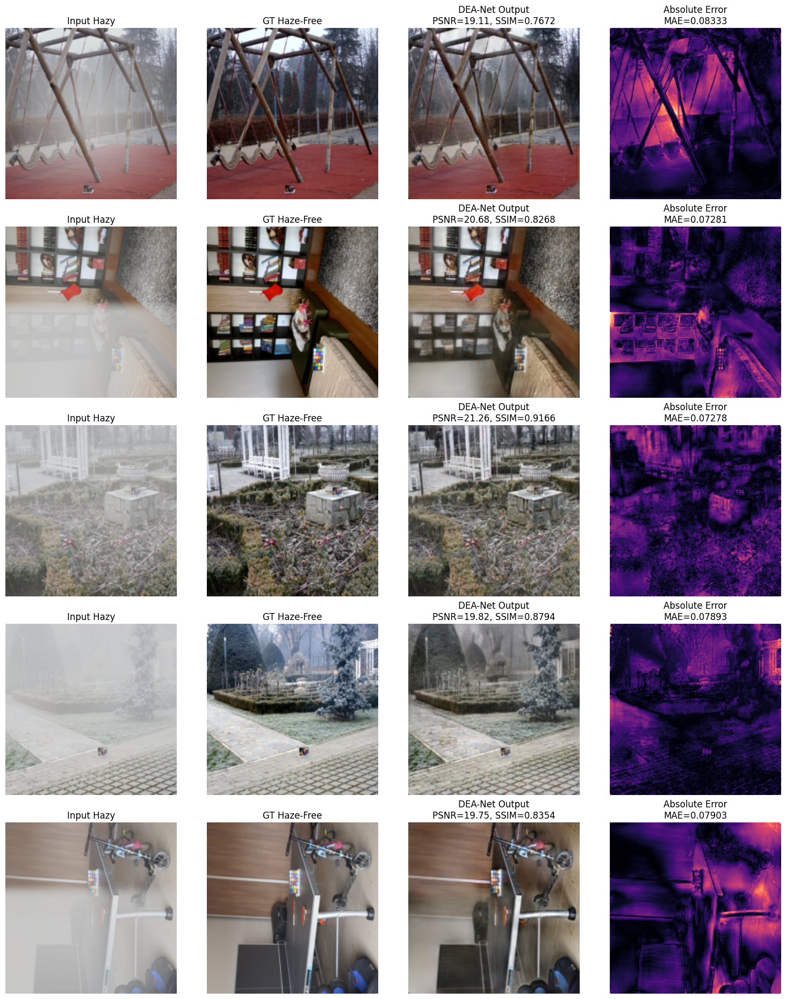

RESIDE


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0046158843..1.0964109].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.047954988..1.017103].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.020004693..1.0713087].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.012263529..1.0938972].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.049019217..1.0801708].


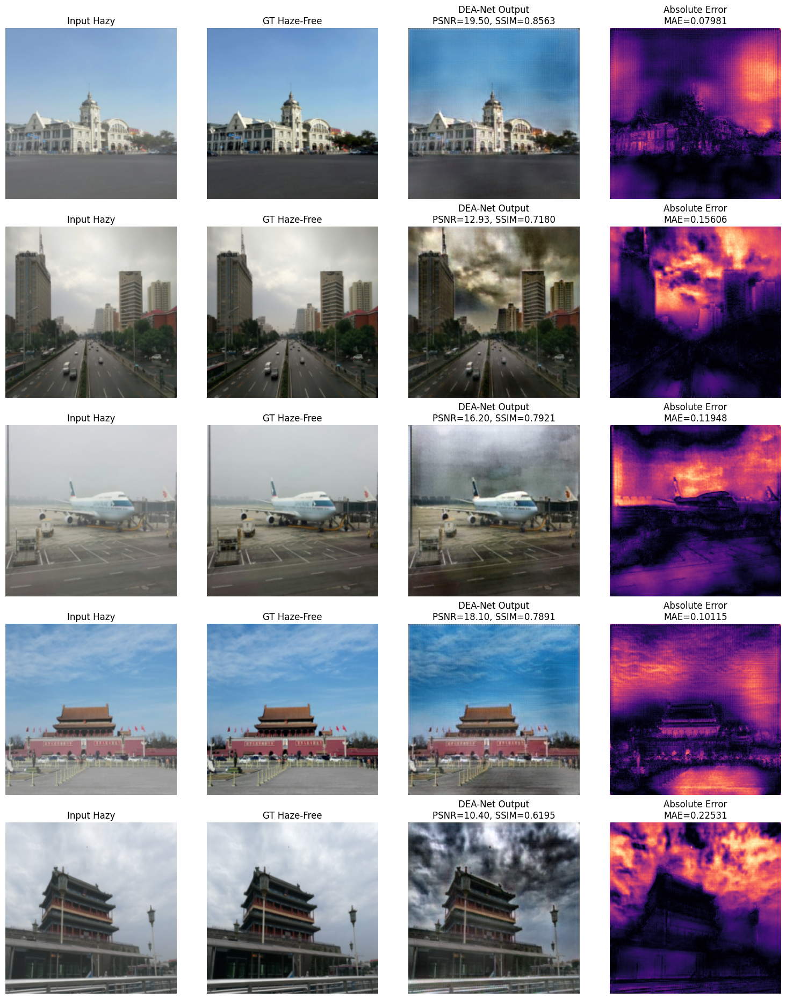

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.00753247..1.1537517].


reside-6k


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.023488455..1.2819228].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.042791173..1.0787266].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.029827323..1.1501617].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.120943755..1.3134828].


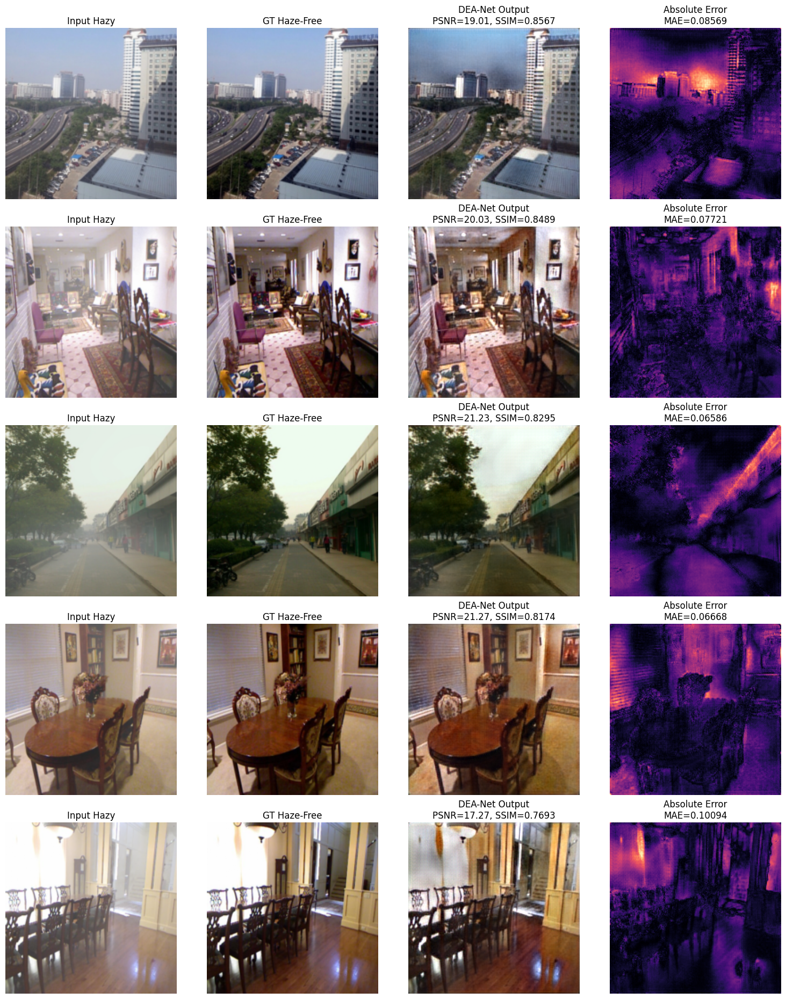

In [10]:
def show_subjective_comparison(model, dataset, n=5):
    model.eval()
    indices = random.sample(range(len(dataset)), min(n, len(dataset)))
    fig, axes = plt.subplots(len(indices), 4, figsize=(15, 3.7 * len(indices)), constrained_layout=True)
    if len(indices) == 1: axes = axes[None, :]
    with torch.no_grad():
        for row, idx in enumerate(indices):
            item = dataset[idx]
            hazy, gt = item["hazy"], item["gt"]
            pred = model(hazy.unsqueeze(0).to(device)).squeeze(0).cpu()
            hazy_np, gt_np, pred_np = [x.permute(1, 2, 0).numpy() for x in (hazy, gt, pred)]
            scores = dehaze_metrics(pred_np, gt_np)
            panels = [(hazy_np, "Input Hazy"), (gt_np, "GT Haze-Free"), (pred_np, f"DEA-Net Output\nPSNR={scores['PSNR']:.2f}, SSIM={scores['SSIM']:.4f}"), (np.abs(pred_np - gt_np).mean(-1), f"Absolute Error\nMAE={scores['MAE']:.5f}")]
            for col, (image, title) in enumerate(panels):
                axes[row, col].imshow(image, cmap="magma" if col == 3 else None)
                axes[row, col].set_title(title); axes[row, col].axis("off")
    plt.show()

for name, dataset in test_datasets.items():
    print(name)
    show_subjective_comparison(model, dataset, n=5)


## Model Summary and Presentation Export


Model: DEANet
Trainable parameters: 7,789,313


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.007920442..1.0422069].


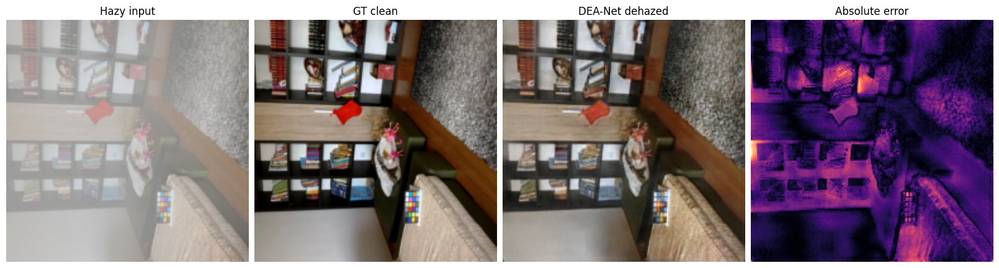

Saved: /kaggle/working/deanet_nhd/deanet_NHD_dataset_sample_000.png


,PSNR,SSIM,MAE,RMSE
0,20.963,0.8504,0.0707,0.0895


In [11]:
def export_presentation_sample(model, dataset, sample_index=0, output_dir=None):
    output_dir = output_dir or cfg.OUT_DIR
    os.makedirs(output_dir, exist_ok=True)
    item = dataset[sample_index]
    model.eval()
    with torch.no_grad():
        pred = model(item["hazy"].unsqueeze(0).to(device)).squeeze(0).cpu()
    hazy, gt, pred = [x.permute(1, 2, 0).numpy() for x in (item["hazy"], item["gt"], pred)]
    error = np.abs(pred - gt).mean(-1)
    scores = dehaze_metrics(pred, gt)
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), constrained_layout=True)
    for ax, image, title in zip(axes, [hazy, gt, pred, error], ["Hazy input", "GT clean", "DEA-Net dehazed", "Absolute error"]):
        ax.imshow(image, cmap="magma" if title == "Absolute error" else None)
        ax.set_title(title); ax.axis("off")
    path = os.path.join(output_dir, f"deanet_{dataset.dataset_name}_sample_{sample_index:03d}.png")
    fig.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()
    print("Saved:", path)
    display(pd.DataFrame([scores]).round(4))
    return path, scores

print(f"Model: {model.__class__.__name__}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")
presentation_panel_path, presentation_sample_metrics = export_presentation_sample(model, test_dataset, sample_index=0)